In [ ]:
# ==========================================
# Google Drive Mount
# ==========================================

from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ==========================================
# Import Required Libraries
# ==========================================

# Basic
import os
import random
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Image processing
from PIL import Image

# TensorFlow / Keras
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    Embedding,
    LSTM,
    Bidirectional,
    Concatenate,
    GlobalAveragePooling2D,
    Attention
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.applications import (
    EfficientNetB3,
    ResNet152
)

from tensorflow.keras.applications.efficientnet import (
    preprocess_input as efficientnet_preprocess
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)


# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)


# Progress bar
from tqdm.auto import tqdm


# Ignore warnings
import warnings
warnings.filterwarnings("ignore")


# Check TensorFlow and GPU

print("TensorFlow version:", tf.__version__)

print(
    "GPU Available:",
    tf.config.list_physical_devices('GPU')
)

TensorFlow version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# ==========================================
# Load Multimodal Dataset
# ==========================================

# Dataset path
file_path = "/content/dataset.xlsx"


# Load Excel
df = pd.read_excel(file_path)


# Display first rows
df.head()

,description,path,category
0,"A photograph of a young man with short, tousle...","""G:\My Drive\photo\Photos\A_00382.jpg""",Real
1,A close-up photograph of a smiling young man w...,"""G:\My Drive\photo\Photos\A_00383.jpg""",Real
2,A photograph of a young man with short light b...,"""G:\My Drive\photo\Photos\A_00384.jpg""",Real
3,A portrait of a young man with neatly styled b...,"""G:\My Drive\photo\Photos\A_00385.jpg""",Real
4,A cheerful young woman wearing a wide-brimmed ...,"""G:\My Drive\photo\Photos\A_00386.jpg""",Real


In [ ]:
# ==========================================
# Dataset Basic Diagnostics
# ==========================================

print("Dataset Shape:")
print(df.shape)


print("\nColumn Names:")
print(df.columns.tolist())


print("\nData Types:")
print(df.dtypes)


print("\nMissing Values:")
print(df.isnull().sum())


print("\nDataset Information:")
df.info()

Dataset Shape:
(1200, 3)

Column Names:
['description', 'path', 'category']

Data Types:
description    object
path           object
category       object
dtype: object

Missing Values:
description    0
path           0
category       0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   description  1200 non-null   object
 1   path         1200 non-null   object
 2   category     1200 non-null   object
dtypes: object(3)
memory usage: 28.3+ KB


Class Distribution:
category
Real    700
Fake    500
Name: count, dtype: int64

Class Percentage:
category
Real    58.33
Fake    41.67
Name: proportion, dtype: float64


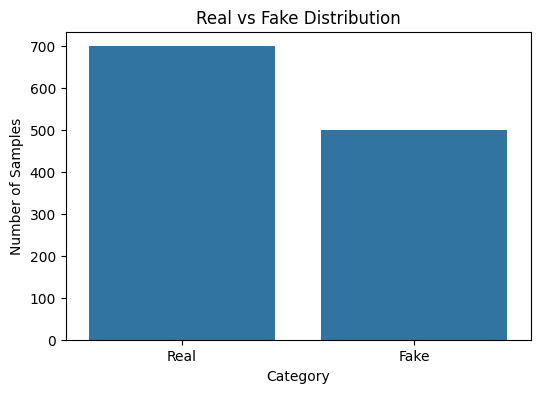

In [ ]:
# ==========================================
# Label Distribution Analysis
# ==========================================

print("Class Distribution:")
print(df['category'].value_counts())


print("\nClass Percentage:")
print(
    df['category']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


# Visualization

plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x='category'
)

plt.title("Real vs Fake Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Samples")

plt.show()

In [ ]:
# ==========================================
# Convert Windows Paths to Google Drive Paths
# ==========================================

image_folder = "/content/drive/MyDrive/photo/Photos"


# Extract filename correctly
df['image_name'] = df['path'].apply(
    lambda x: x.replace('"','').replace('\\','/').split('/')[-1]
)


# Create Colab path
df['path'] = df['image_name'].apply(
    lambda x: os.path.join(image_folder, x)
)


# Check result
df[['image_name','path']].head()

,image_name,path
0,A_00382.jpg,/content/drive/MyDrive/photo/Photos/A_00382.jpg
1,A_00383.jpg,/content/drive/MyDrive/photo/Photos/A_00383.jpg
2,A_00384.jpg,/content/drive/MyDrive/photo/Photos/A_00384.jpg
3,A_00385.jpg,/content/drive/MyDrive/photo/Photos/A_00385.jpg
4,A_00386.jpg,/content/drive/MyDrive/photo/Photos/A_00386.jpg


In [ ]:
# ==========================================
# Verify Image Availability
# ==========================================

df['image_exists'] = df['path'].apply(os.path.exists)


print(df['image_exists'].value_counts())


print(
    "\nMissing Images:",
    len(df[df['image_exists']==False])
)

image_exists
True    1200
Name: count, dtype: int64

Missing Images: 0


Real Samples


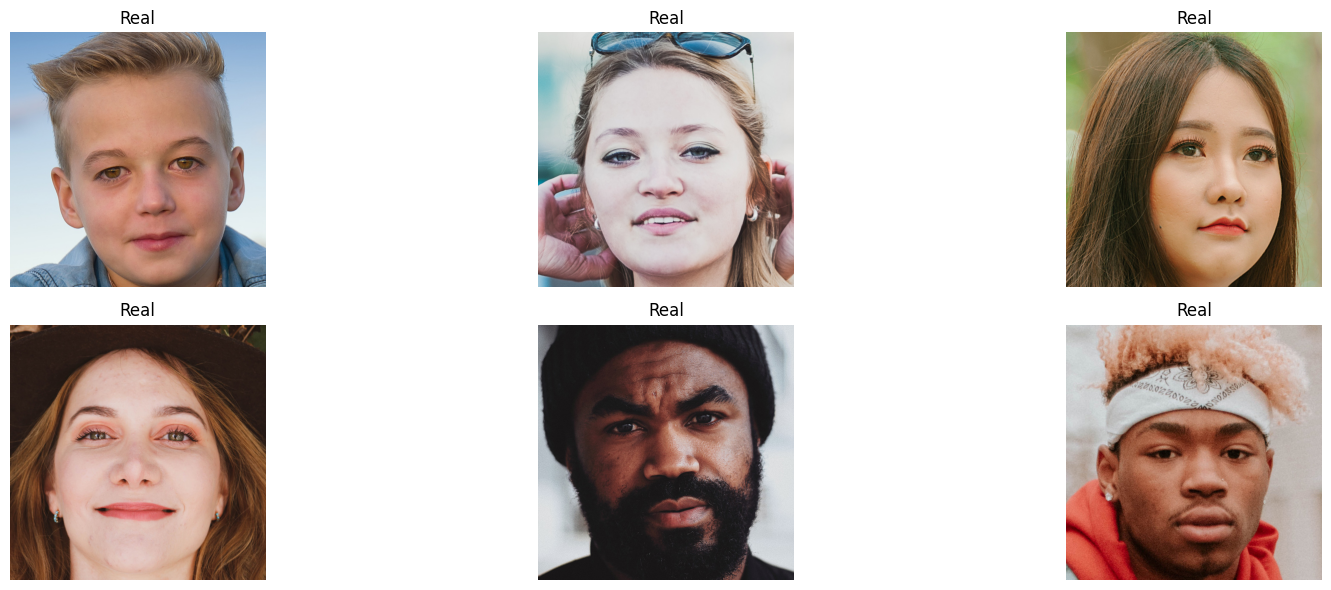

Fake Samples


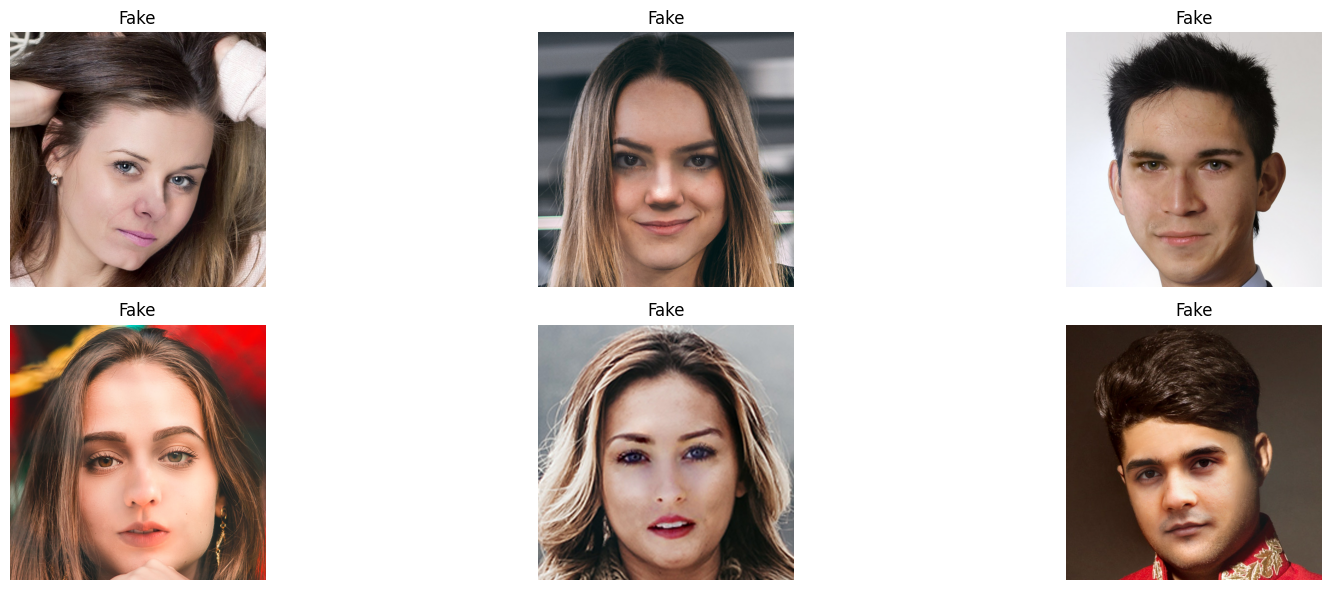

In [ ]:
# ==========================================
# Visual Inspection of Images
# ==========================================

def display_samples(label, n=6):

    samples = df[df['category']==label].sample(
        n,
        random_state=42
    )

    plt.figure(figsize=(18,6))

    for i, row in enumerate(samples.itertuples()):

        img = Image.open(row.path)

        plt.subplot(2,3,i+1)
        plt.imshow(img)
        plt.axis("off")
        plt.title(label)

    plt.tight_layout()
    plt.show()


print("Real Samples")
display_samples("Real",6)


print("Fake Samples")
display_samples("Fake",6)

count    1200.000000
mean       40.558333
std        16.786495
min         1.000000
25%        25.000000
50%        38.000000
75%        54.000000
max       104.000000
Name: text_length, dtype: float64

Class-wise text length:
          count   mean        std   min   25%   50%    75%    max
category                                                         
Fake      500.0  52.05  12.114496   1.0  45.0  52.0  60.00   90.0
Real      700.0  32.35  14.718885  13.0  23.0  27.0  37.25  104.0


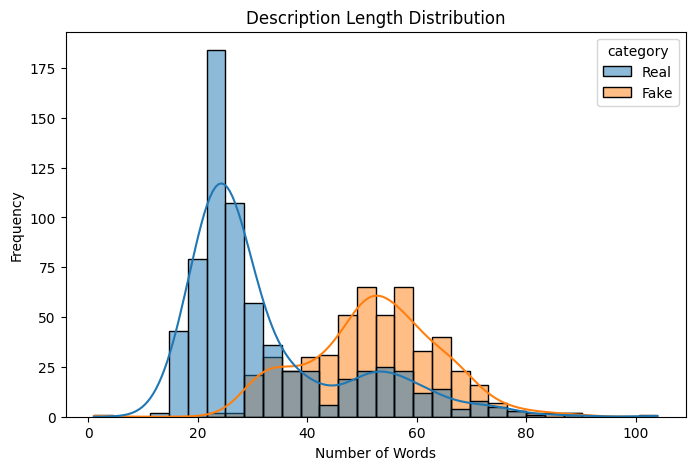

In [ ]:
# ==========================================
# Text Length Analysis for LSTM
# ==========================================

df['text_length'] = df['description'].apply(
    lambda x: len(str(x).split())
)


print(df['text_length'].describe())


print("\nClass-wise text length:")
print(
    df.groupby('category')['text_length'].describe()
)


plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='text_length',
    hue='category',
    bins=30,
    kde=True
)

plt.title("Description Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [ ]:
# ==========================================
# Encode Labels
# ==========================================

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df['label'] = label_encoder.fit_transform(
    df['category']
)


print(label_encoder.classes_)

print(df[['category','label']].head())

['Fake' 'Real']
  category  label
0     Real      1
1     Real      1
2     Real      1
3     Real      1
4     Real      1


In [ ]:
# ==========================================
# Stratified Train Validation Test Split
# ==========================================

from sklearn.model_selection import train_test_split


# First split:
# 70% train, 30% temp

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df['label'],
    random_state=42
)


# Second split:
# 15% validation, 15% test

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df['label'],
    random_state=42
)


print("Train size:", train_df.shape)
print("Validation size:", val_df.shape)
print("Test size:", test_df.shape)


print("\nTrain distribution:")
print(train_df['category'].value_counts(normalize=True))


print("\nValidation distribution:")
print(val_df['category'].value_counts(normalize=True))


print("\nTest distribution:")
print(test_df['category'].value_counts(normalize=True))

Train size: (840, 7)
Validation size: (180, 7)
Test size: (180, 7)

Train distribution:
category
Real    0.583333
Fake    0.416667
Name: proportion, dtype: float64

Validation distribution:
category
Real    0.583333
Fake    0.416667
Name: proportion, dtype: float64

Test distribution:
category
Real    0.583333
Fake    0.416667
Name: proportion, dtype: float64


In [ ]:
# ==========================================
# Text Tokenization for LSTM
# ==========================================

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences


# Parameters
MAX_WORDS = 5000
MAX_LENGTH = 100


# Create tokenizer
tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)


# Fit ONLY on training descriptions
tokenizer.fit_on_texts(
    train_df['description'].astype(str)
)


# Convert text to sequences

train_sequences = tokenizer.texts_to_sequences(
    train_df['description'].astype(str)
)

val_sequences = tokenizer.texts_to_sequences(
    val_df['description'].astype(str)
)

test_sequences = tokenizer.texts_to_sequences(
    test_df['description'].astype(str)
)


# Padding

X_train_text = pad_sequences(
    train_sequences,
    maxlen=MAX_LENGTH,
    padding='post',
    truncating='post'
)

X_val_text = pad_sequences(
    val_sequences,
    maxlen=MAX_LENGTH,
    padding='post',
    truncating='post'
)

X_test_text = pad_sequences(
    test_sequences,
    maxlen=MAX_LENGTH,
    padding='post',
    truncating='post'
)


print("Vocabulary size:",
      len(tokenizer.word_index))

print("\nText input shapes:")
print("Train:", X_train_text.shape)
print("Validation:", X_val_text.shape)
print("Test:", X_test_text.shape)

Vocabulary size: 1245

Text input shapes:
Train: (840, 100)
Validation: (180, 100)
Test: (180, 100)


In [ ]:
# ==========================================
# Download GloVe 300D Embeddings
# ==========================================

!wget -q http://nlp.stanford.edu/data/glove.6B.zip

!unzip -q glove.6B.zip

In [ ]:
# ==========================================
# Create GloVe Embedding Matrix
# ==========================================

EMBEDDING_DIM = 300

glove_path = "glove.6B.300d.txt"


# Load GloVe vectors

embeddings_index = {}

with open(glove_path, encoding="utf8") as f:
    for line in f:
        values = line.split()

        word = values[0]

        vector = np.asarray(
            values[1:],
            dtype="float32"
        )

        embeddings_index[word] = vector


print("Total GloVe words:",
      len(embeddings_index))

Total GloVe words: 400000


In [ ]:
# ==========================================
# Build Embedding Matrix
# ==========================================

vocab_size = min(
    MAX_WORDS,
    len(tokenizer.word_index) + 1
)


embedding_matrix = np.zeros(
    (vocab_size, EMBEDDING_DIM)
)


for word, i in tokenizer.word_index.items():

    if i < vocab_size:

        embedding_vector = embeddings_index.get(word)

        if embedding_vector is not None:

            embedding_matrix[i] = embedding_vector


print("Embedding matrix shape:",
      embedding_matrix.shape)

Embedding matrix shape: (1246, 300)


In [ ]:
# ==========================================
# Custom Attention Layer
# ==========================================

class AttentionLayer(tf.keras.layers.Layer):

    def __init__(self):
        super(AttentionLayer, self).__init__()

    def build(self, input_shape):

        self.W = self.add_weight(
            name="attention_weight",
            shape=(input_shape[-1], 1),
            initializer="random_normal",
            trainable=True
        )

        self.b = self.add_weight(
            name="attention_bias",
            shape=(input_shape[1], 1),
            initializer="zeros",
            trainable=True
        )


    def call(self, inputs):

        # Calculate attention scores
        score = tf.nn.tanh(
            tf.matmul(inputs, self.W)
            + self.b
        )

        attention_weights = tf.nn.softmax(
            score,
            axis=1
        )

        context_vector = (
            attention_weights * inputs
        )

        context_vector = tf.reduce_sum(
            context_vector,
            axis=1
        )

        return context_vector

In [ ]:
# ==========================================
# Cell 17: Text Functional API Branch
# ==========================================

from tensorflow.keras.layers import (
    Input,
    Embedding,
    Bidirectional,
    LSTM,
    Dense,
    Dropout
)


# Text input
text_input = Input(
    shape=(MAX_LENGTH,),
    name="text_input"
)


# GloVe Embedding Layer

text_embedding = Embedding(
    input_dim=vocab_size,
    output_dim=EMBEDDING_DIM,
    weights=[embedding_matrix],
    input_length=MAX_LENGTH,
    trainable=False,
    name="glove_embedding"
)(text_input)



# BiLSTM layer
text_lstm = Bidirectional(
    LSTM(
        units=128,
        return_sequences=True,
        dropout=0.3,
        recurrent_dropout=0.2
    ),
    name="bidirectional_lstm"
)(text_embedding)



# Attention layer
text_attention = AttentionLayer()(
    text_lstm
)



# Dense projection
text_features = Dense(
    256,
    activation="relu",
    name="text_dense"
)(text_attention)


text_features = Dropout(
    0.3,
    name="text_dropout"
)(text_features)


print("Text branch created successfully")

Text branch created successfully


In [ ]:
# ==========================================
# Verify Text Branch Architecture
# ==========================================

text_model = Model(
    inputs=text_input,
    outputs=text_features
)

text_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_input (InputLayer)         │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ glove_embedding (Embedding)     │ (None, 100, 300)       │       373,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_lstm              │ (None, 100, 256)       │       439,296 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_layer                 │ (None, 256)            │           356 │
│ (AttentionLayer)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ text_dense (Dense)              │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ text_dropout (Dropout)          │ (None, 256)            │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 879,244 (3.35 MB)

 Trainable params: 505,444 (1.93 MB)

 Non-trainable params: 373,800 (1.43 MB)

In [ ]:
# ==========================================
# Cell 18: Image Functional API Branch
# With Data Augmentation
# ==========================================

from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    RandomFlip,
    RandomRotation,
    RandomZoom,
    RandomContrast
)

from tensorflow.keras.applications import EfficientNetB3


# Image input

image_input = Input(
    shape=(224,224,3),
    name="image_input"
)


# Data augmentation
# Applied only during training

data_augmentation = tf.keras.Sequential(
    [
        RandomFlip(
            "horizontal"
        ),

        RandomRotation(
            0.05
        ),

        RandomZoom(
            0.1
        ),

        RandomContrast(
            0.1
        )
    ],
    name="image_augmentation"
)


# Apply augmentation

augmented_image = data_augmentation(
    image_input
)


# EfficientNetB3

efficientnet = EfficientNetB3(
    include_top=False,
    weights="imagenet",
    input_tensor=augmented_image
)


# Keep backbone frozen

efficientnet.trainable = False


# Feature extraction

image_features = GlobalAveragePooling2D(
    name="image_global_pool"
)(
    efficientnet.output
)


# Projection

image_features = Dense(
    256,
    activation="relu",
    name="image_dense"
)(
    image_features
)


image_features = Dropout(
    0.3,
    name="image_dropout"
)(
    image_features
)


print("Image branch with augmentation created successfully")

43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Image branch with augmentation created successfully


In [ ]:
# ==========================================
# Verify Image Branch Architecture
# ==========================================

image_model = Model(
    inputs=image_input,
    outputs=image_features
)

image_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_augmentation  │ (None, 224, 224,  │          0 │ image_input[0][0] │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ image_augmentati… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │      1,080 │ stem_conv_pad[0]… │
│                     │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        160 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        360 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        160 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 40)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 40)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 10)  │        410 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 40)  │        440 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati

 Total params: 11,177,007 (42.64 MB)

 Trainable params: 393,472 (1.50 MB)

 Non-trainable params: 10,783,535 (41.14 MB)

In [ ]:
# ==========================================
# Cell 19: Multimodal Fusion Network
# ==========================================

from tensorflow.keras.layers import Concatenate


# Combine image and text features

fusion = Concatenate(
    name="feature_fusion"
)(
    [
        text_features,
        image_features
    ]
)


# Fusion dense layers

x = Dense(
    256,
    activation="relu",
    name="fusion_dense_1"
)(fusion)


x = Dropout(
    0.4,
    name="fusion_dropout_1"
)(x)


x = Dense(
    64,
    activation="relu",
    name="fusion_dense_2"
)(x)


x = Dropout(
    0.3,
    name="fusion_dropout_2"
)(x)


# Binary output

output = Dense(
    1,
    activation="sigmoid",
    name="fake_probability"
)(x)


print("Fusion network created successfully")

Fusion network created successfully


In [ ]:
# ==========================================
# Cell 20: Create Final Functional API Model
# ==========================================

multimodal_model = Model(
    inputs=[
        image_input,
        text_input
    ],
    outputs=output,
    name="Multimodal_AI_Image_Detection"
)


# Model summary

multimodal_model.summary()

Model: "Multimodal_AI_Image_Detection"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_augmentation  │ (None, 224, 224,  │          0 │ image_input[0][0] │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ image_augmentati… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │      1,080 │ stem_conv_pad[0]… │
│                     │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        160 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        360 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        160 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 40)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 40)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 10)  │        410 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 40)  │        440 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati

 Total params: 12,204,092 (46.55 MB)

 Trainable params: 1,046,757 (3.99 MB)

 Non-trainable params: 11,157,335 (42.56 MB)

In [ ]:
# ==========================================
# Cell 21: Compile Multimodal Model
# ==========================================

from tensorflow.keras.optimizers import Adam


multimodal_model.compile(
    optimizer=Adam(
        learning_rate=1e-4
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)


print("Model compiled successfully")

Model compiled successfully


In [ ]:
# ==========================================
# Cell 22: Image Preprocessing Function
# ==========================================

IMG_SIZE = 224


def preprocess_image(path):

    # Read image
    image = tf.io.read_file(path)

    # Decode JPEG
    image = tf.image.decode_jpeg(
        image,
        channels=3
    )

    # Resize
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    # EfficientNet preprocessing
    image = tf.keras.applications.efficientnet.preprocess_input(
        image
    )

    return image


print("Image preprocessing function ready")

Image preprocessing function ready


In [ ]:
# ==========================================
# Cell 23: TensorFlow Dataset Generator
# ==========================================


def create_dataset(
    dataframe,
    text_sequences,
    batch_size=16,
    shuffle=True
):

    # Image paths
    image_paths = dataframe['path'].values


    # Labels
    labels = dataframe['label'].values


    # Create dataset

    dataset = tf.data.Dataset.from_tensor_slices(
        (
            {
                "image_input": image_paths,
                "text_input": text_sequences
            },
            labels
        )
    )


    # Preprocessing function

    def process_data(inputs, label):

        image = preprocess_image(
            inputs["image_input"]
        )


        text = inputs["text_input"]


        return (
            {
                "image_input": image,
                "text_input": text
            },
            label
        )


    # Apply preprocessing

    dataset = dataset.map(
        process_data,
        num_parallel_calls=tf.data.AUTOTUNE
    )


    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )


    dataset = dataset.batch(
        batch_size
    )


    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )


    return dataset



print("Dataset creation function ready")

Dataset creation function ready


In [ ]:
# ==========================================
# Cell 24: Create TensorFlow Datasets
# ==========================================

BATCH_SIZE = 16


train_dataset = create_dataset(
    train_df,
    X_train_text,
    batch_size=BATCH_SIZE,
    shuffle=True
)


val_dataset = create_dataset(
    val_df,
    X_val_text,
    batch_size=BATCH_SIZE,
    shuffle=False
)


test_dataset = create_dataset(
    test_df,
    X_test_text,
    batch_size=BATCH_SIZE,
    shuffle=False
)


print("Train batches:", tf.data.experimental.cardinality(train_dataset))
print("Validation batches:", tf.data.experimental.cardinality(val_dataset))
print("Test batches:", tf.data.experimental.cardinality(test_dataset))

Train batches: tf.Tensor(53, shape=(), dtype=int64)
Validation batches: tf.Tensor(12, shape=(), dtype=int64)
Test batches: tf.Tensor(12, shape=(), dtype=int64)


In [ ]:
# ==========================================
# Cell 25: Check Dataset Batch Shapes
# ==========================================


for batch_inputs, batch_labels in train_dataset.take(1):

    print("Image input shape:")
    print(
        batch_inputs["image_input"].shape
    )


    print("\nText input shape:")
    print(
        batch_inputs["text_input"].shape
    )


    print("\nLabel shape:")
    print(
        batch_labels.shape
    )

Image input shape:
(16, 224, 224, 3)

Text input shape:
(16, 100)

Label shape:
(16,)


In [ ]:
# ==========================================
# Cell 26: Training Callbacks
# ==========================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)


checkpoint_path = "/content/drive/MyDrive/best_multimodal_model.keras"


early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)


checkpoint = ModelCheckpoint(
    filepath=checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)


reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=3,
    min_lr=1e-7,
    verbose=1
)


callbacks = [
    early_stop,
    checkpoint,
    reduce_lr
]


print("Callbacks ready")

Callbacks ready


In [ ]:
# ==========================================
# Cell 27: Train Multimodal Model
# ==========================================

history = multimodal_model.fit(
    train_dataset,

    validation_data=val_dataset,

    epochs=30,

    callbacks=callbacks,

    verbose=1
)

Epoch 1/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 544ms/step - accuracy: 0.5401 - auc: 0.5178 - loss: 0.7040 - precision: 0.6363 - recall: 0.5775
Epoch 1: val_loss improved from None to 0.66517, saving model to /content/drive/MyDrive/best_multimodal_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/best_multimodal_model.keras
53/53 ━━━━━━━━━━━━━━━━━━━━ 153s 2s/step - accuracy: 0.5440 - auc: 0.5335 - loss: 0.6882 - precision: 0.5918 - recall: 0.7041 - val_accuracy: 0.5889 - val_auc: 0.6223 - val_loss: 0.6652 - val_precision: 0.5886 - val_recall: 0.9810 - learning_rate: 1.0000e-04
Epoch 2/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 562ms/step - accuracy: 0.6208 - auc: 0.6231 - loss: 0.6552 - precision: 0.6363 - recall: 0.8369
Epoch 2: val_loss improved from 0.66517 to 0.62703, saving model to /content/drive/MyDrive/best_multimodal_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/best_multimodal_model.keras
53/53 ━━━━━━━━━━━━━━━━━━━━ 40s 649ms/step - accuracy: 0.6202 

In [ ]:
# ==========================================
# Cell 28: Test Evaluation
# ==========================================

test_results = multimodal_model.evaluate(
    test_dataset,
    verbose=1
)


print("\nTest Results:")

for name, value in zip(
    multimodal_model.metrics_names,
    test_results
):
    print(f"{name}: {value:.4f}")

12/12 ━━━━━━━━━━━━━━━━━━━━ 68s 6s/step - accuracy: 0.8333 - auc: 0.9082 - loss: 0.4307 - precision: 0.9310 - recall: 0.7714

Test Results:
loss: 0.4307
compile_metrics: 0.8333


In [ ]:
# ==========================================
# Cell 29: Detailed Test Evaluation
# ==========================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)


# Get predictions

y_true = []
y_prob = []


for batch_inputs, labels in test_dataset:

    predictions = multimodal_model.predict(
        batch_inputs,
        verbose=0
    )

    y_prob.extend(
        predictions.flatten()
    )

    y_true.extend(
        labels.numpy()
    )


# Convert

y_true = np.array(y_true)
y_prob = np.array(y_prob)


# Binary prediction

y_pred = (y_prob >= 0.5).astype(int)


print("Classification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Fake",
            "Real"
        ]
    )
)


print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_true,
        y_pred
    )
)


print("\nROC-AUC:")

print(
    roc_auc_score(
        y_true,
        y_prob
    )
)

Classification Report:

              precision    recall  f1-score   support

        Fake       0.74      0.92      0.82        75
        Real       0.93      0.77      0.84       105

    accuracy                           0.83       180
   macro avg       0.84      0.85      0.83       180
weighted avg       0.85      0.83      0.83       180


Confusion Matrix:
[[69  6]
 [24 81]]

ROC-AUC:
0.909968253968254


In [ ]:
# ==========================================
# Cell 30: Threshold Analysis
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

thresholds = np.arange(
    0.30,
    0.71,
    0.05
)


results = []


for threshold in thresholds:

    # Generate predictions
    y_pred_threshold = (
        y_prob >= threshold
    ).astype(int)


    # Metrics

    accuracy = accuracy_score(
        y_true,
        y_pred_threshold
    )


    # Fake class = 0
    fake_recall = recall_score(
        y_true,
        y_pred_threshold,
        pos_label=0
    )


    real_recall = recall_score(
        y_true,
        y_pred_threshold,
        pos_label=1
    )


    fake_f1 = f1_score(
        y_true,
        y_pred_threshold,
        pos_label=0
    )


    macro_f1 = f1_score(
        y_true,
        y_pred_threshold,
        average="macro"
    )


    results.append([
        threshold,
        accuracy,
        fake_recall,
        real_recall,
        fake_f1,
        macro_f1
    ])


threshold_df = pd.DataFrame(
    results,
    columns=[
        "Threshold",
        "Accuracy",
        "Fake_Recall",
        "Real_Recall",
        "Fake_F1",
        "Macro_F1"
    ]
)


threshold_df

,Threshold,Accuracy,Fake_Recall,Real_Recall,Fake_F1,Macro_F1
0,0.30,0.822222,0.826667,0.819048,0.794872,0.819005
1,0.35,0.827778,0.880000,0.790476,0.809816,0.826228
2,0.40,0.827778,0.880000,0.790476,0.809816,0.826228
3,0.45,0.827778,0.893333,0.780952,0.812121,0.826573
4,0.50,0.833333,0.920000,0.771429,0.821429,0.832589
5,0.55,0.816667,0.920000,0.742857,0.807018,0.816207
6,0.60,0.811111,0.920000,0.733333,0.802326,0.810737
7,0.65,0.794444,0.933333,0.695238,0.790960,0.794387
8,0.70,0.805556,0.960000,0.695238,0.804469,0.805550


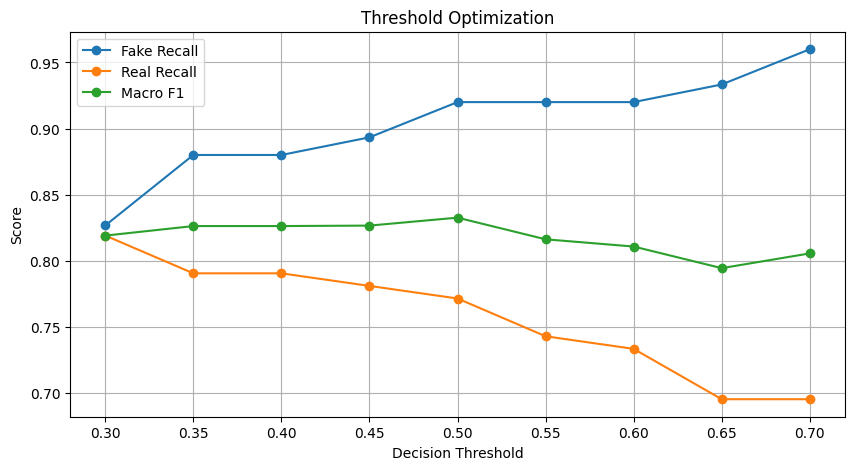

In [ ]:
# ==========================================
# Threshold Performance Plot
# ==========================================

plt.figure(figsize=(10,5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Fake_Recall"],
    marker="o",
    label="Fake Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Real_Recall"],
    marker="o",
    label="Real Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Macro_F1"],
    marker="o",
    label="Macro F1"
)


plt.xlabel("Decision Threshold")
plt.ylabel("Score")

plt.title(
    "Threshold Optimization"
)

plt.legend()
plt.grid(True)

plt.show()